In [1]:
# ---------- Step 1: Import libraries ----------
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# ---------- Step 2: Load the data ----------
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)   # features (inputs)
y = data.target                                            # labels: 0 = malignant, 1 = benign

print("Shape of data:", X.shape)          # (569, 30) -> 569 patients, 30 features
print(X.head())

# ---------- Step 3: Split into training and testing sets ----------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ---------- Step 4: Feature scaling ----------
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   # learn mean/std from training data
X_test  = scaler.transform(X_test)        # apply the same scaling to test data

# ---------- Step 5: Train models ----------
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train, y_train)

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# ---------- Step 6: Evaluate ----------
for name, model in [("Logistic Regression", log_model), ("Random Forest", rf_model)]:
    y_pred = model.predict(X_test)
    print(f"\n===== {name} =====")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, target_names=data.target_names))

# ---------- Step 7: Predict for a new patient ----------
new_patient = X_test[0].reshape(1, -1)
result = rf_model.predict(new_patient)[0]
print("\nPrediction for new patient:", data.target_names[result])

Shape of data: (569, 30)
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst 

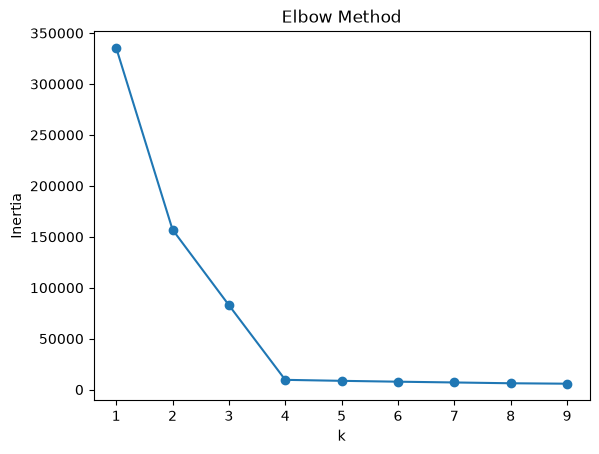

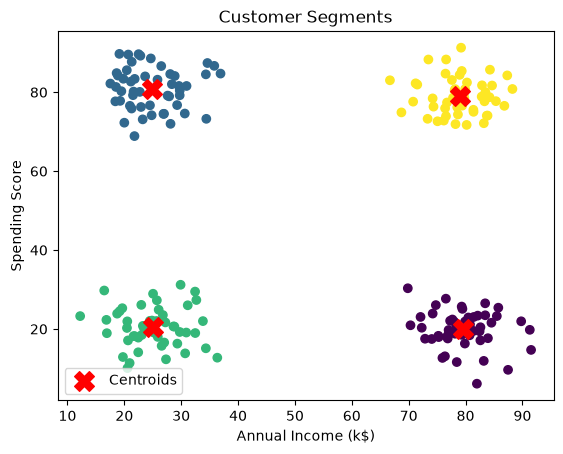

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Synthetic customer data: [annual income (k$), spending score (1-100)]
np.random.seed(0)
customers = np.vstack([
    np.random.normal([25, 20], 5, (50, 2)),   # low income, low spending
    np.random.normal([25, 80], 5, (50, 2)),   # low income, high spending
    np.random.normal([80, 20], 5, (50, 2)),   # high income, low spending
    np.random.normal([80, 80], 5, (50, 2)),   # high income, high spending (VIP)
])

# Elbow method: find the best number of clusters
inertia = []
for k in range(1, 10):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(customers)
    inertia.append(km.inertia_)
plt.plot(range(1, 10), inertia, marker='o'); plt.title("Elbow Method")
plt.xlabel("k"); plt.ylabel("Inertia"); plt.show()

# Train with k = 4
kmeans = KMeans(n_clusters=4, n_init=10, random_state=0)
labels = kmeans.fit_predict(customers)

plt.scatter(customers[:, 0], customers[:, 1], c=labels, cmap='viridis')
plt.scatter(*kmeans.cluster_centers_.T, c='red', marker='X', s=200, label='Centroids')
plt.xlabel("Annual Income (k$)"); plt.ylabel("Spending Score")
plt.title("Customer Segments"); plt.legend(); plt.show()